In [48]:
# Load libraries and save them as variables
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Imported tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All Libraries successfully imported!")

All Libraries successfully imported!


In [49]:
# Loads the Iris dataset saved as "iris.csv" 
iris_dataset = pd.read_csv("iris.csv")

# Display the first ten rows
iris_dataset.head(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [50]:
# Checks the size of the dataset
print("Dataset shape:", iris_dataset.shape)

# Checks for missing values
print("\nMissing values:")
print(iris_dataset.isnull().sum())

# Counts each flower species
print("\nSpecies distribution:")
print(iris_dataset["species"].value_counts())

# Show statistical information (count, mean, std, min/max, quartiles)
iris_dataset.describe()

Dataset shape: (150, 5)

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Exploratory Data Analysis (EDA)

To better understand the Iris dataset, scatter plots and a correlation heatmap were used to explore the relationships between the different flower measurements. The scatter plots help visualize how the three species differ based on their features, while the heatmap highlights correlations between the numerical variables. These visualizations provide insight into patterns within the dataset and help identify which features may be useful for species classification.

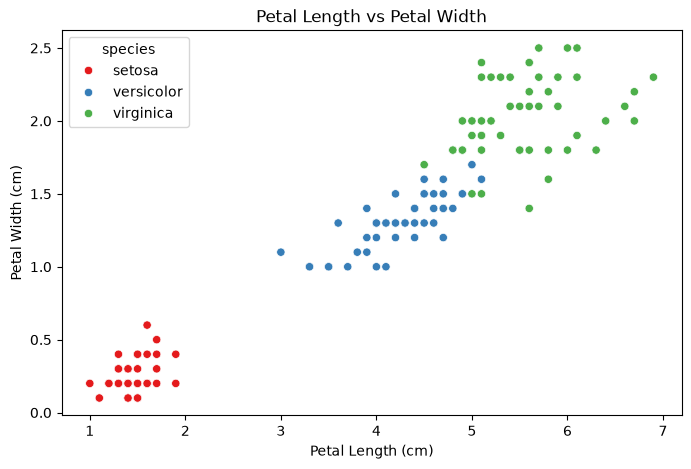

In [51]:
# Specifies width and height in inches
plt.figure(figsize=(8, 5))

#Creates a scatter plot, each flower is represented by a dot
sns.scatterplot(
    data=iris_dataset,
    x="petal_length",
    y="petal_width",
    hue="species",
    palette="Set1"
)

# Sets Graph details and display
plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.show()

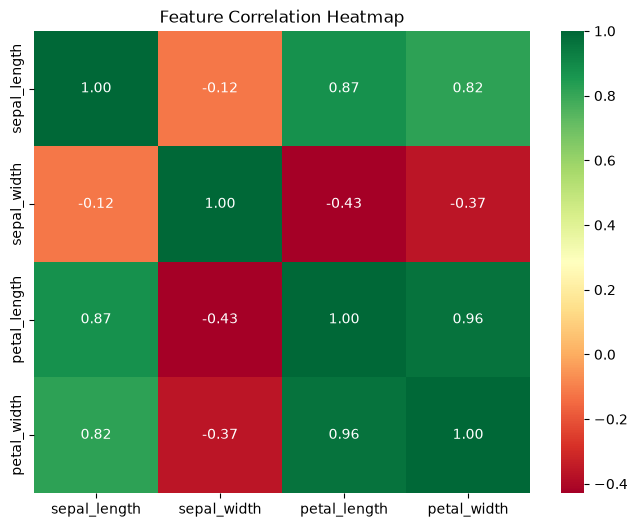

In [52]:
# Specifies width and height in inches
plt.figure(figsize=(8, 6))

# Displays correlations using colored squares (heat map)
sns.heatmap(
    #Temporarily removes species column from the data. (Species contain text. We need numerical measurements)
    iris_dataset.drop(columns=["species"]).corr(),
    annot=True,
    cmap="RdYlGn",
    fmt=".2f"
)

# Sets Graph details and display
plt.title("Feature Correlation Heatmap")
plt.show()

## Data Preprocessing

To prepare the dataset for model training, the data is divided into two subsets, with 80% allocated for training and the remaining 20% reserved for testing. Feature scaling is then performed using StandardScaler to standardize the numerical features, ensuring they are on a comparable scale. This helps prevent features with larger values from having a disproportionate influence on the model and supports more consistent training and evaluation.

In [53]:
# Measurements used for prediction
features = iris_dataset.drop(columns=["species"])

# Flower species
labels = iris_dataset["species"]

# Split into 80% training and 20% testing
features_train, features_test, labels_train, labels_test = train_test_split(
    features,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

# Returning Outputs
print("Training samples:", len(features_train))
print("Testing samples:", len(labels_test))

Training samples: 120
Testing samples: 30


In [54]:
# Create standardization object
scaler = StandardScaler()

# Learn scaling values from training data
features_train_scaled = scaler.fit_transform(features_train)

# Apply the same scaling to testing data
features_test_scaled = scaler.transform(features_test)

print("Feature scaling completed!")

Feature scaling completed!


## Model Training

Two classification algorithms, Logistic Regression and Decision Tree, are used to train models on the Iris dataset. Each model learns patterns from the training data to predict flower species based on their measurements. Both models are then evaluated using the testing dataset to assess their prediction accuracy and compare their overall performance.

In [55]:
# Creates the Logistic Regression model
log_model = LogisticRegression(max_iter=1000, random_state=42)

# Trains the model using scaled training data
log_model.fit(features_train_scaled, labels_train)

# Predicts species for the test data
log_predictions = log_model.predict(features_test_scaled)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [56]:
# Create the Decision Tree model
tree_model = DecisionTreeClassifier(random_state=42)

# Trains using the original training data
tree_model.fit(features_train, labels_train)

# Predicts species for the test data
tree_predictions = tree_model.predict(features_test)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


## Model Evaluation and Comparison

To assess and compare the performance of the Logistic Regression and Decision Tree models, several evaluation metrics are used, including accuracy, precision, recall, and F1-score. These metrics provide insight into how effectively each model classifies the Iris flower species using the testing dataset. The results are then compared to determine which model performs better and provides more reliable predictions.

In [57]:
# Imports evaluation functions
from sklearn.metrics import precision_score, recall_score, f1_score

# Creates an empty list
results = []

# Loops through each model and its predictions
for name, predictions in [
    ("Logistic Regression", log_predictions),
    ("Decision Tree", tree_predictions)
]:
    # Adds an item to the list
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(labels_test, predictions),
        "Precision": precision_score(labels_test, predictions, average="macro"),
        "Recall": recall_score(labels_test, predictions, average="macro"),
        "F1 Score": f1_score(labels_test, predictions, average="macro")
    })

results_data = pd.DataFrame(results)

display(results_data.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933


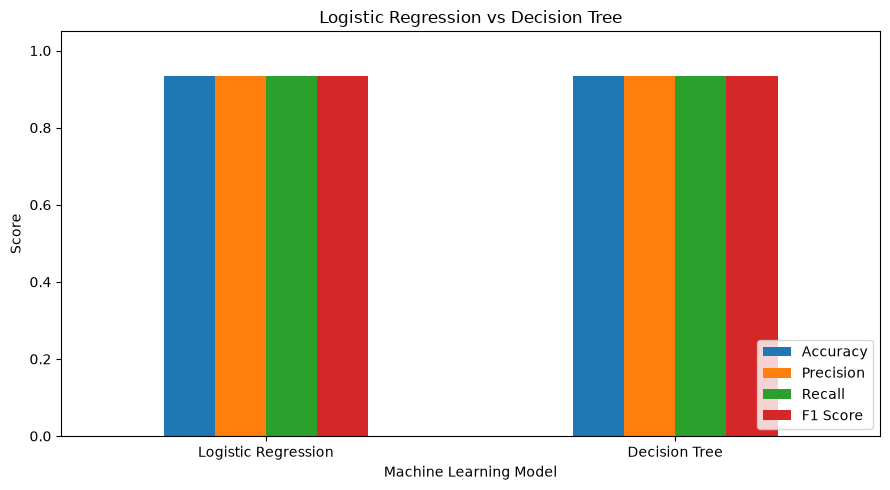

In [58]:
# Uses model names as row labels, and creates a graph from the DataFrame
results_data.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1.05),
    rot=0
)

# Bar graph details and display
plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Confusion Matrix Analysis

To further evaluate the performance of both classification models, confusion matrices are used to visualize the number of correct and incorrect predictions for each Iris species. These matrices provide a clearer understanding of how accurately each model distinguishes between the different species and highlight any classification errors. This analysis helps identify potential weaknesses in the models and supports a more detailed comparison of their performance.

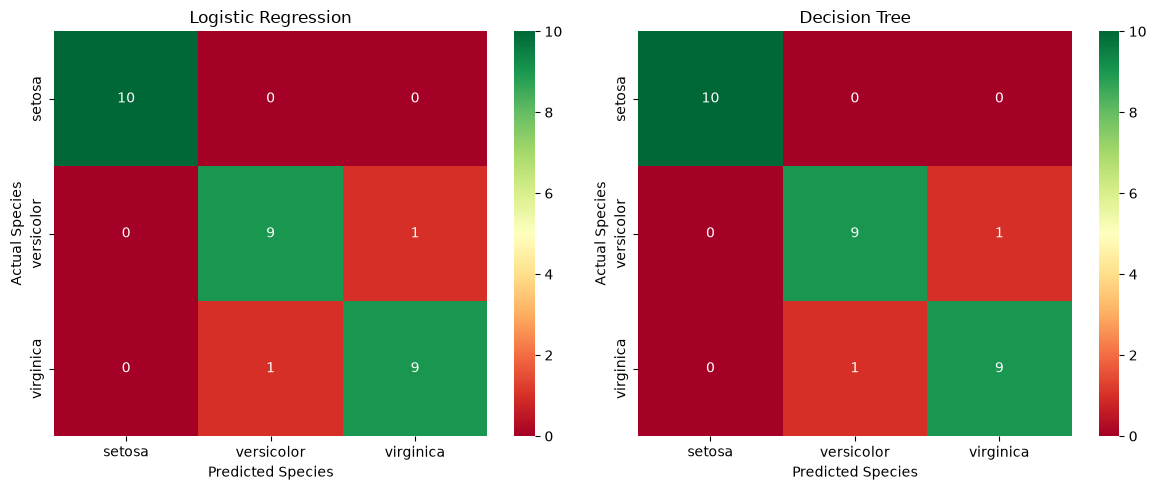

In [59]:
# Creates two plotting areas side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Stores models names and predictions
models = [
    ("Logistic Regression", log_predictions),
    ("Decision Tree", tree_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(
        labels_test,
        predictions,
        labels=["setosa", "versicolor", "virginica"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="RdYlGn",
        xticklabels=["setosa", "versicolor", "virginica"],
        yticklabels=["setosa", "versicolor", "virginica"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

## ROC Curve Analysis

ROC curves are used to further evaluate how effectively the classification models distinguish between the three Iris species. Since the dataset contains multiple classes, a one-vs-rest approach is used to calculate a separate curve for each species. The Area Under the Curve (AUC) provides an additional measure of how well each model separates the different classes.

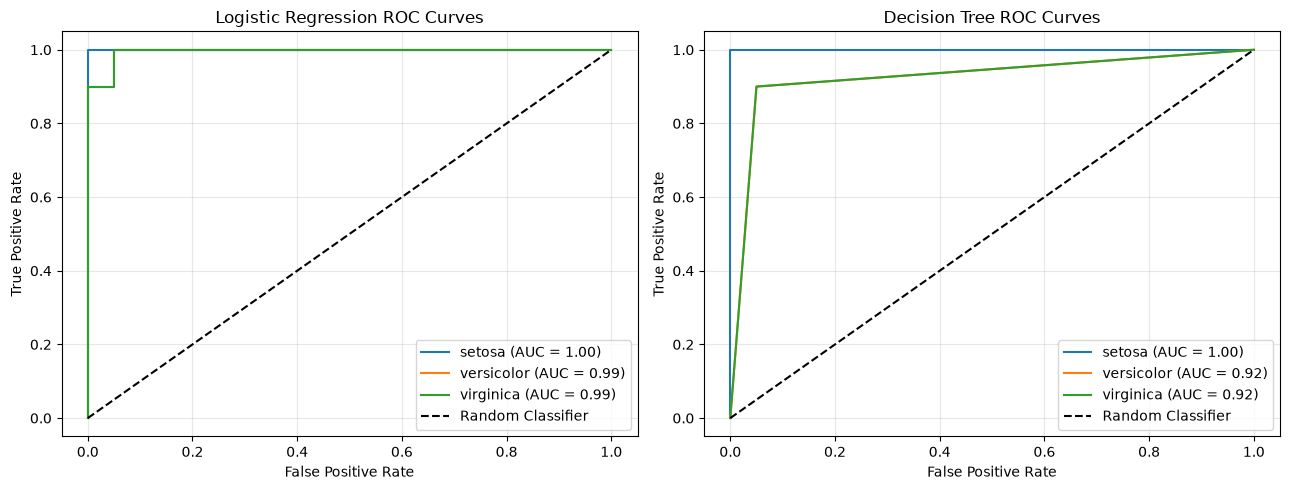

In [60]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Get the species names in the same order for both models
species_names = log_model.classes_

# Convert the actual species labels into binary values
labels_test_binary = label_binarize(labels_test, classes=species_names)

# Calculate prediction probabilities for each model
log_probabilities = log_model.predict_proba(features_test_scaled)
tree_probabilities = tree_model.predict_proba(features_test)

# Create two graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loop through each model and its prediction probabilities
for ax, model_name, probabilities in [
    (axes[0], "Logistic Regression", log_probabilities),
    (axes[1], "Decision Tree", tree_probabilities)
]:
    # Calculate a separate ROC curve for each species
    for index, species in enumerate(species_names):
        false_positive_rate, true_positive_rate, thresholds = roc_curve(
            labels_test_binary[:, index],
            probabilities[:, index]
        )

        auc_score = auc(false_positive_rate, true_positive_rate)

        ax.plot(
            false_positive_rate,
            true_positive_rate,
            label=f"{species} (AUC = {auc_score:.2f})"
        )

    # Add a reference line representing random classification
    ax.plot([0, 1], [0, 1], "k--", label="Random Classifier")

    ax.set_title(f"{model_name} ROC Curves")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Feature Importance Analysis

Feature importance is used to examine which flower measurements have the greatest influence on the Decision Tree model's predictions. The importance scores are visualized using a bar chart, making it easier to compare the contribution of each feature to the classification process.

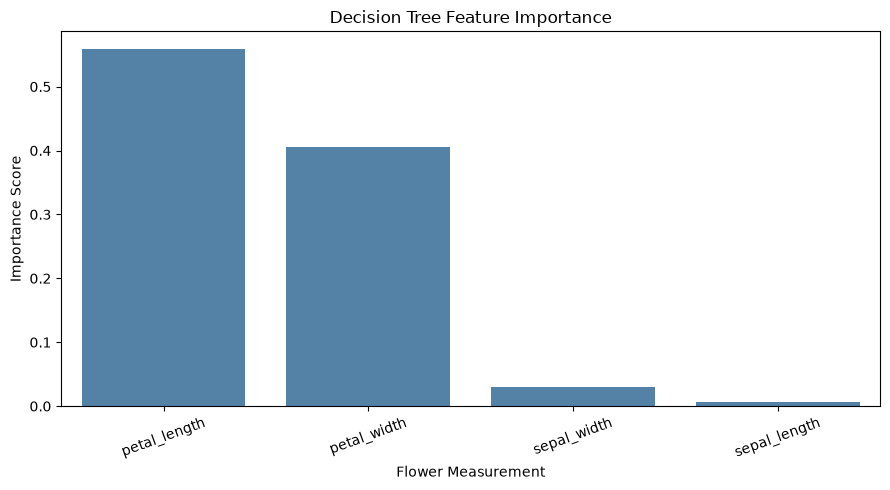

In [61]:
# Get the importance score for each feature
importance_scores = tree_model.feature_importances_

# Create a DataFrame containing feature names and scores
feature_importance_data = pd.DataFrame({
    "Feature": features_train.columns,
    "Importance": importance_scores
})

# Sort features from highest to lowest importance
feature_importance_data = feature_importance_data.sort_values(
    by="Importance",
    ascending=False
)

# Create the feature importance bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance_data,
    x="Feature",
    y="Importance",
    color="steelblue"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Flower Measurement")
plt.ylabel("Importance Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Decision Boundary Visualization

To better understand how the Logistic Regression and Decision Tree models classify the Iris species, decision boundaries are visualized using petal length and petal width. These visualizations illustrate how each model separates the three species based on the selected features and highlight differences in their classification approaches. This provides a clearer understanding of how the models make predictions and how effectively they distinguish between the different flower species.

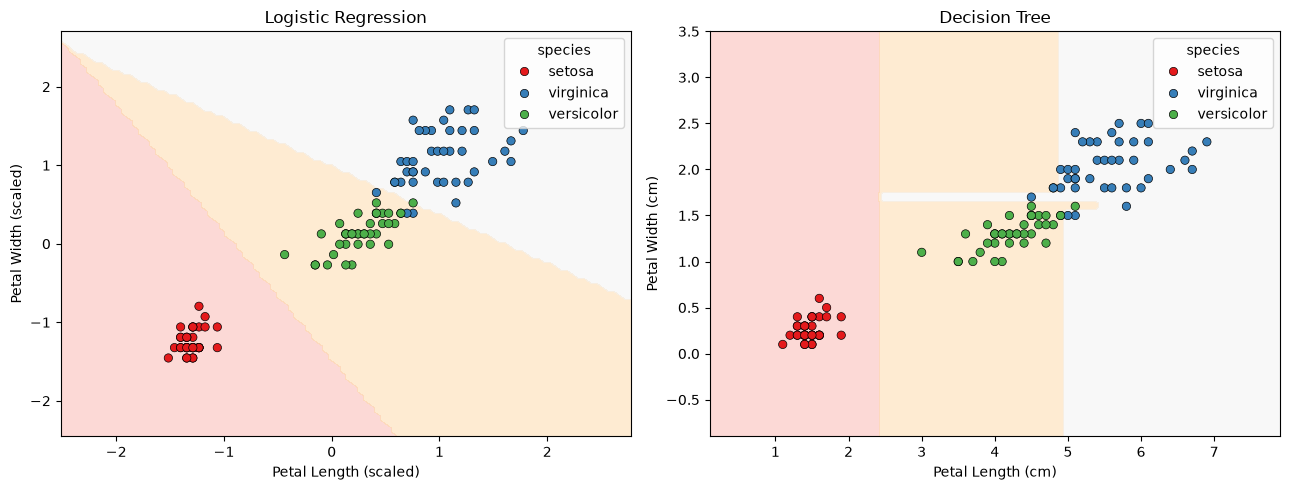

In [62]:
from sklearn.inspection import DecisionBoundaryDisplay

# Select two features for visualization
features = ["petal_length", "petal_width"]

features_train_2d = features_train[features]
features_test_2d = features_test[features]

# Scale the two features
scaler_2d = StandardScaler()
features_train_2d_scaled = scaler_2d.fit_transform(features_train_2d)

# Train separate models for 2D visualization
log_2d = LogisticRegression(max_iter=1000, random_state=42)
log_2d.fit(features_train_2d_scaled, labels_train)

tree_2d = DecisionTreeClassifier(random_state=42)
tree_2d.fit(features_train_2d, labels_train)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loops through and unpacks the graph settings
for ax, model, data, title in [
    (axes[0], log_2d, features_train_2d_scaled, "Logistic Regression"),
    (axes[1], tree_2d, features_train_2d, "Decision Tree")
]:
    DecisionBoundaryDisplay.from_estimator(
        model,
        data,
        response_method="predict",
        multiclass_colors="Pastel1",
        ax=ax,
        alpha=0.5
    )

    sns.scatterplot(
        x=data[:, 0] if isinstance(data, np.ndarray) else data.iloc[:, 0],
        y=data[:, 1] if isinstance(data, np.ndarray) else data.iloc[:, 1],
        hue=labels_train,
        palette="Set1",
        ax=ax,
        edgecolor="black"
    )

    ax.set_title(title)
    ax.set_xlabel("Petal Length" + (" (scaled)" if title == "Logistic Regression" else " (cm)"))
    ax.set_ylabel("Petal Width" + (" (scaled)" if title == "Logistic Regression" else " (cm)"))

plt.tight_layout()
plt.show()

## Conclusion

This project focused on using the Iris dataset to train and evaluate two machine learning classification models: Logistic Regression and Decision Tree.

The dataset consisted of 150 flower samples across three species. The data was explored using visualizations, checked for missing values, and divided into 80% training data and 20% testing data. StandardScaler was applied to standardize the features used for Logistic Regression.

Both models achieved an accuracy of **93.3%**, correctly classifying 28 out of 30 samples in the test dataset. Additional evaluation metrics, including precision, recall, and F1-score, were used to compare their performance.

The ROC curve analysis showed that Logistic Regression achieved slightly higher AUC scores than the Decision Tree for Versicolor and Virginica, while both models performed equally well for Setosa. The feature importance analysis also highlighted that petal length and petal width were the most influential measurements in the Decision Tree model.

Overall, the results demonstrate that both algorithms can effectively classify Iris flower species, although they approach classification differently. The project provided practical experience with data exploration, preprocessing, model training, evaluation, and visualization.